In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import sys
import pandas as pd
import numpy as np
import sklearn
import scipy
import pyarrow
import joblib
from IPython.display import display

# 1. Đường dẫn dùng chung với Hưng
BASE = Path("/content/drive/MyDrive/hmda")
SETUP_DIR = BASE / "rq4_setup"
LR_DIR = BASE / "rq4_logistic"

config_path = SETUP_DIR / "master_modeling_config.json"

assert config_path.is_file(), (
    f"Chưa tìm thấy: {config_path}\n"
    "Kiểm tra shortcut folder hmda trong MyDrive."
)

with open(config_path, "r", encoding="utf-8") as f:
    master_config = json.load(f)

# 2. Đọc thiết lập đã chốt
configs = master_config["configurations"]
artifacts = master_config["shared_artifacts"]
feature_config = configs["feature_selection"]

FEATURES = feature_config["features"]
TARGET = feature_config["target"]
GROUP = feature_config["group"]
N_SPLITS = feature_config["n_splits"]
RANDOM_STATE = master_config["random_state"]

DATA_PATH = Path(master_config["data_path"])

# 3. Kiểm tra các file cần dùng
required_paths = {
    "Modeling data": DATA_PATH,
    "Master configuration": config_path,
    "Lender train/test split":
        SETUP_DIR / artifacts["lender_split"],
    "Saved train/test indices":
        SETUP_DIR / artifacts["train_test_indices"],
    "Lender CV folds":
        SETUP_DIR / artifacts["cv_fold_assignment"],
    "Saved CV fold array":
        SETUP_DIR / artifacts["cv_fold_array"],
    "Gradient Boosting preprocessor":
        SETUP_DIR / artifacts["gb_preprocessor"],
    "Evaluation utilities":
        SETUP_DIR / artifacts["evaluation_module"],
    "Logistic Regression summary":
        LR_DIR / "lr_model_summary.json",
}

handoff_check = pd.DataFrame([
    {
        "item": name,
        "exists": path.exists(),
        "path": str(path),
    }
    for name, path in required_paths.items()
])

print("BẢNG 1 — KIỂM TRA FILE BÀN GIAO")
display(handoff_check)

assert handoff_check["exists"].all(), (
    "Có file chưa tìm thấy. Gửi bảng kiểm tra để xử lý."
)

# 4. Kiểm tra phiên bản phần mềm trước khi nạp preprocessor
current_versions = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__,
    "pyarrow": pyarrow.__version__,
    "joblib": joblib.__version__,
}

saved_versions = master_config.get("software_versions", {})

version_check = pd.DataFrame([
    {
        "software": name,
        "hung_version": saved_versions.get(name, "Not recorded"),
        "your_version": version,
        "same_version": saved_versions.get(name) == version,
    }
    for name, version in current_versions.items()
])

print("\nBẢNG 2 — PHIÊN BẢN PHẦN MỀM")
display(version_check)

# 5. Tạo nơi lưu kết quả riêng của bạn
GB_OUT = Path(
    "/content/drive/MyDrive/HMDA_Thuy/rq4_gradient_boosting"
)
GB_OUT.mkdir(parents=True, exist_ok=True)

handoff_check.to_csv(
    GB_OUT / "00_handoff_file_check.csv",
    index=False,
    encoding="utf-8-sig",
)

version_check.to_csv(
    GB_OUT / "01_environment_check.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nSố biến đầu vào:", len(FEATURES))
print("Số fold:", N_SPLITS)
print("Target:", TARGET)
print("Cột dùng để chia nhóm:", GROUP)
print("Nguồn dữ liệu:", DATA_PATH)

print("\nPASS — đã tìm đủ file bàn giao.")
print("Chưa nạp dữ liệu lớn hoặc huấn luyện mô hình.")

Mounted at /content/drive
BẢNG 1 — KIỂM TRA FILE BÀN GIAO


,item,exists,path
0,Modeling data,True,/content/drive/MyDrive/hmda/clean_pandas/S1_or...
1,Master configuration,True,/content/drive/MyDrive/hmda/rq4_setup/master_m...
2,Lender train/test split,True,/content/drive/MyDrive/hmda/rq4_setup/lender_t...
3,Saved train/test indices,True,/content/drive/MyDrive/hmda/rq4_setup/train_te...
4,Lender CV folds,True,/content/drive/MyDrive/hmda/rq4_setup/lender_c...
5,Saved CV fold array,True,/content/drive/MyDrive/hmda/rq4_setup/cv_fold_...
6,Gradient Boosting preprocessor,True,/content/drive/MyDrive/hmda/rq4_setup/gb_prepr...
7,Evaluation utilities,True,/content/drive/MyDrive/hmda/rq4_setup/evaluati...
8,Logistic Regression summary,True,/content/drive/MyDrive/hmda/rq4_logistic/lr_mo...



BẢNG 2 — PHIÊN BẢN PHẦN MỀM


,software,hung_version,your_version,same_version
0,python,3.13.18,3.13.18,True
1,numpy,2.4.6,2.4.6,True
2,pandas,2.2.3,2.2.3,True
3,scipy,1.16.3,1.16.3,True
4,scikit_learn,1.6.1,1.6.1,True
5,pyarrow,23.0.1,23.0.1,True
6,joblib,1.6.0,1.6.0,True



Số biến đầu vào: 12
Số fold: 5
Target: denied_flag
Cột dùng để chia nhóm: lei
Nguồn dữ liệu: /content/drive/MyDrive/hmda/clean_pandas/S1_orig_denied

PASS — đã tìm đủ file bàn giao.
Chưa nạp dữ liệu lớn hoặc huấn luyện mô hình.


In [ ]:
import gc
import time
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import display

start = time.perf_counter()

NUMERIC_FEATURES = feature_config["numeric_features"]
CATEGORICAL_FEATURES = feature_config["categorical_features"]

# 1. Đọc đúng nguồn và các cột Hưng đã dùng
print("Đang đọc dữ liệu S1...", flush=True)

model_cols = FEATURES + [TARGET, GROUP]

table = pq.read_table(
    str(DATA_PATH),
    columns=model_cols,
)

# Chuẩn hóa kiểu dictionary của Arrow trước khi chuyển sang Pandas
for i, field in enumerate(table.schema):
    if pa.types.is_dictionary(field.type):
        table = table.set_column(
            i,
            field.name,
            table.column(i).cast(field.type.value_type),
        )

model_df = table.to_pandas(strings_to_categorical=True)

del table
gc.collect()

# Giữ kiểu dữ liệu giống notebook Logistic Regression
for col in NUMERIC_FEATURES:
    model_df[col] = model_df[col].astype("float32")

for col in CATEGORICAL_FEATURES + [GROUP]:
    model_df[col] = model_df[col].astype("category")

assert model_df[TARGET].isin([0, 1]).all()
assert model_df[GROUP].notna().all()

model_df[TARGET] = model_df[TARGET].astype("int8")

assert not np.isinf(
    model_df[NUMERIC_FEATURES].to_numpy()
).any(), "Có giá trị vô cực cần kiểm tra."

# 2. Khôi phục train/test theo danh sách lender đã lưu
print("Đang khôi phục train/test...", flush=True)

lender_split = pd.read_csv(
    SETUP_DIR / artifacts["lender_split"],
    dtype={GROUP: str},
)

assert lender_split[GROUP].is_unique

partition_map = lender_split.set_index(GROUP)["partition"]
partition_assignment = model_df[GROUP].map(partition_map)

assert partition_assignment.notna().all()
assert partition_assignment.isin(["train", "test"]).all()

train_idx = np.flatnonzero(
    partition_assignment.eq("train").to_numpy()
)
test_idx = np.flatnonzero(
    partition_assignment.eq("test").to_numpy()
)

# Kiểm tra cả thứ tự dòng, không chỉ số lượng
with np.load(
    SETUP_DIR / artifacts["train_test_indices"]
) as saved_indices:
    assert np.array_equal(
        train_idx, saved_indices["train_idx"]
    ), "Thứ tự hồ sơ train khác thiết lập Hưng."

    assert np.array_equal(
        test_idx, saved_indices["test_idx"]
    ), "Thứ tự hồ sơ test khác thiết lập Hưng."

# 3. Khôi phục năm fold theo lender
print("Đang khôi phục năm fold...", flush=True)

cv_lender_split = pd.read_csv(
    SETUP_DIR / artifacts["cv_fold_assignment"],
    dtype={GROUP: str},
)

assert cv_lender_split[GROUP].is_unique

cv_fold_map = cv_lender_split.set_index(GROUP)["validation_fold"]

groups_train = (
    model_df[GROUP].iloc[train_idx].reset_index(drop=True)
)
groups_test = (
    model_df[GROUP].iloc[test_idx].reset_index(drop=True)
)

mapped_folds = groups_train.map(cv_fold_map)
assert mapped_folds.notna().all()

fold_assignment = mapped_folds.to_numpy(dtype=np.int8)

saved_folds = np.load(
    SETUP_DIR / artifacts["cv_fold_array"]
)

assert np.array_equal(
    fold_assignment, saved_folds
), "Fold hoặc thứ tự hồ sơ khác thiết lập Hưng."

assert set(np.unique(fold_assignment)) == set(
    range(1, N_SPLITS + 1)
)

# 4. Tạo dữ liệu đầu vào và nhãn
X_train = (
    model_df.iloc[train_idx][FEATURES].reset_index(drop=True)
)
X_test = (
    model_df.iloc[test_idx][FEATURES].reset_index(drop=True)
)

y_train = model_df[TARGET].to_numpy()[train_idx]
y_test = model_df[TARGET].to_numpy()[test_idx]

# 5. Kiểm tra quy mô và lender không trùng
population = master_config["population"]

assert len(model_df) == population["total_applications"]
assert len(X_train) == population["training_applications"]
assert len(X_test) == population["test_applications"]
assert len(train_idx) + len(test_idx) == len(model_df)

assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_test)) == {0, 1}

train_lenders = set(groups_train)
test_lenders = set(groups_test)

assert train_lenders.isdisjoint(test_lenders), \
    "Có lender xuất hiện ở cả train và test."

partition_summary = pd.DataFrame([
    {
        "partition": name,
        "applications": len(y),
        "lenders": groups.nunique(),
        "originated": int((y == 0).sum()),
        "denied": int((y == 1).sum()),
        "denial_rate_pct": y.mean() * 100,
    }
    for name, y, groups in [
        ("Train", y_train, groups_train),
        ("Test", y_test, groups_test),
    ]
])

# 6. Kiểm tra từng fold không bị trùng lender
fold_rows = []

for fold in range(1, N_SPLITS + 1):
    fit_mask = fold_assignment != fold
    val_mask = fold_assignment == fold

    fit_lenders = set(groups_train[fit_mask])
    val_lenders = set(groups_train[val_mask])

    overlap = len(fit_lenders.intersection(val_lenders))
    assert overlap == 0
    assert set(np.unique(y_train[fit_mask])) == {0, 1}
    assert set(np.unique(y_train[val_mask])) == {0, 1}

    fold_rows.append({
        "fold": fold,
        "fit_applications": int(fit_mask.sum()),
        "validation_applications": int(val_mask.sum()),
        "validation_lenders": len(val_lenders),
        "validation_denial_rate_pct":
            y_train[val_mask].mean() * 100,
        "lender_overlap": overlap,
    })

fold_summary = pd.DataFrame(fold_rows)

print("\nBẢNG 1 — TRAIN/TEST")
display(partition_summary.round(4))

print("\nBẢNG 2 — NĂM FOLD TRONG TẬP TRAIN")
display(fold_summary.round(4))

# 7. Lưu bằng chứng kiểm tra
partition_summary.to_csv(
    GB_OUT / "02_partition_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

fold_summary.to_csv(
    GB_OUT / "03_fold_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# Giải phóng bảng trung gian
del model_df, partition_assignment, saved_folds, mapped_folds
gc.collect()

print(f"\nThời gian: {time.perf_counter() - start:.1f} giây")
print("PASS — train/test, thứ tự hồ sơ và năm fold khớp Hưng.")
print("Chưa huấn luyện mô hình.")

Đang đọc dữ liệu S1...
Đang khôi phục train/test...
Đang khôi phục năm fold...

BẢNG 1 — TRAIN/TEST


,partition,applications,lenders,originated,denied,denial_rate_pct
0,Train,6308273,3927,4698384,1609889,25.5203
1,Test,1992274,982,1498701,493573,24.7744



BẢNG 2 — NĂM FOLD TRONG TẬP TRAIN


,fold,fit_applications,validation_applications,validation_lenders,validation_denial_rate_pct,lender_overlap
0,1,5046618,1261655,782,22.1451,0
1,2,5046618,1261655,786,30.5966,0
2,3,5046618,1261655,787,24.0303,0
3,4,5046619,1261654,786,23.8347,0
4,5,5046619,1261654,786,26.9946,0



Thời gian: 38.8 giây
PASS — train/test, thứ tự hồ sơ và năm fold khớp Hưng.
Chưa huấn luyện mô hình.


In [ ]:
import gc
import time
import joblib
import numpy as np
import pandas as pd
import psutil

from scipy import sparse
from sklearn.base import clone
from IPython.display import display

start = time.perf_counter()

# 1. Nạp bộ tiền xử lý dành riêng cho Gradient Boosting
gb_preprocessor = joblib.load(
    SETUP_DIR / artifacts["gb_preprocessor"]
)

print("Đã nạp bộ tiền xử lý Gradient Boosting.")

# 2. Lấy mẫu nhỏ từ fold 1:
# - học cách tiền xử lý trên phần fit;
# - áp dụng sang phần validation;
# - không đụng đến tập test.
rng = np.random.default_rng(RANDOM_STATE)

fit_pool = np.flatnonzero(fold_assignment != 1)
val_pool = np.flatnonzero(fold_assignment == 1)

smoke_fit_idx = rng.choice(
    fit_pool,
    size=min(50_000, len(fit_pool)),
    replace=False,
)

smoke_val_idx = rng.choice(
    val_pool,
    size=min(5_000, len(val_pool)),
    replace=False,
)

assert set(groups_train.iloc[smoke_fit_idx]).isdisjoint(
    set(groups_train.iloc[smoke_val_idx])
)

# Clone tạo bản riêng để thử.
# Bản gốc vẫn giữ để sử dụng khi huấn luyện chính thức.
smoke_preprocessor = clone(gb_preprocessor)

print("Đang thử tiền xử lý trên mẫu nhỏ...", flush=True)

smoke_fit_encoded = smoke_preprocessor.fit_transform(
    X_train.iloc[smoke_fit_idx]
)

smoke_val_encoded = smoke_preprocessor.transform(
    X_train.iloc[smoke_val_idx]
)

# 3. Kiểm tra đầu ra
assert smoke_fit_encoded.shape[0] == len(smoke_fit_idx)
assert smoke_val_encoded.shape[0] == len(smoke_val_idx)

assert (
    smoke_fit_encoded.shape[1]
    == smoke_val_encoded.shape[1]
)

def inspect_encoded_matrix(matrix, name):
    if sparse.issparse(matrix):
        # Chỉ kiểm tra các phần tử được lưu,
        # không chuyển toàn bộ ma trận sang dạng đặc.
        matrix = matrix.tocsr()
        finite = bool(np.isfinite(matrix.data).all())
        memory_mb = (
            matrix.data.nbytes
            + matrix.indices.nbytes
            + matrix.indptr.nbytes
        ) / 1024**2
    else:
        finite = bool(np.isfinite(matrix).all())
        memory_mb = matrix.nbytes / 1024**2

    assert finite, f"{name} còn giá trị thiếu hoặc vô cực."

    return {
        "sample": name,
        "rows": matrix.shape[0],
        "encoded_columns": matrix.shape[1],
        "sparse_matrix": sparse.issparse(matrix),
        "all_values_finite": finite,
        "matrix_memory_MB": memory_mb,
    }

preprocessing_smoke_check = pd.DataFrame([
    inspect_encoded_matrix(smoke_fit_encoded, "Fit sample"),
    inspect_encoded_matrix(smoke_val_encoded, "Validation sample"),
])

print("\nBẢNG KIỂM TRA TIỀN XỬ LÝ")
display(preprocessing_smoke_check.round(2))

# Lưu tên các cột được tạo trong lần thử
smoke_feature_names = smoke_preprocessor.get_feature_names_out()

assert len(smoke_feature_names) == smoke_fit_encoded.shape[1]

pd.DataFrame({
    "encoded_feature": smoke_feature_names
}).to_csv(
    GB_OUT / "04_smoke_encoded_features.csv",
    index=False,
    encoding="utf-8-sig",
)

preprocessing_smoke_check.to_csv(
    GB_OUT / "05_preprocessing_smoke_check.csv",
    index=False,
    encoding="utf-8-sig",
)

# 4. Giải phóng dữ liệu thử, giữ lại gb_preprocessor bản gốc
del smoke_fit_encoded, smoke_val_encoded, smoke_preprocessor
gc.collect()

ram = psutil.virtual_memory()

print(f"\nRAM tổng: {ram.total / 1024**3:.2f} GB")
print(f"RAM hiện có thể sử dụng: {ram.available / 1024**3:.2f} GB")
print(f"Thời gian kiểm tra: {time.perf_counter() - start:.1f} giây")
print("\nPASS — bộ tiền xử lý hoạt động trên mẫu nhỏ.")
print("Chưa huấn luyện mô hình và chưa sử dụng tập test.")

Đã nạp bộ tiền xử lý Gradient Boosting.
Đang thử tiền xử lý trên mẫu nhỏ...

BẢNG KIỂM TRA TIỀN XỬ LÝ


,sample,rows,encoded_columns,sparse_matrix,all_values_finite,matrix_memory_MB
0,Fit sample,50000,86,True,True,4.87
1,Validation sample,5000,86,True,True,0.49



RAM tổng: 12.67 GB
RAM hiện có thể sử dụng: 9.36 GB
Thời gian kiểm tra: 1.2 giây

PASS — bộ tiền xử lý hoạt động trên mẫu nhỏ.
Chưa huấn luyện mô hình và chưa sử dụng tập test.


In [ ]:
# Chỉ cài nếu Colab chưa có XGBoost
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("xgboost") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])

import xgboost as xgb
import numpy as np
import pandas as pd
import gc
import time
import json

from scipy import sparse
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
)
from IPython.display import display

print("XGBoost version:", xgb.__version__)

# 1. Dùng lại đúng mẫu nhỏ từ bước trước
assert set(groups_train.iloc[smoke_fit_idx]).isdisjoint(
    set(groups_train.iloc[smoke_val_idx])
)

smoke_preprocessor = clone(gb_preprocessor)

# Hàm này cũng sẽ dùng khi chạy mô hình chính thức
def to_xgb_dense_float32(matrix):
    if sparse.issparse(matrix):
        result = matrix.astype(np.float32).toarray()
    else:
        result = np.asarray(matrix, dtype=np.float32)

    result = np.ascontiguousarray(result)
    assert np.isfinite(result).all()
    return result

print("Đang tiền xử lý mẫu nhỏ...", flush=True)

prep_start = time.perf_counter()

smoke_fit_encoded = to_xgb_dense_float32(
    smoke_preprocessor.fit_transform(
        X_train.iloc[smoke_fit_idx]
    )
)

smoke_val_encoded = to_xgb_dense_float32(
    smoke_preprocessor.transform(
        X_train.iloc[smoke_val_idx]
    )
)

preprocessing_seconds = time.perf_counter() - prep_start

smoke_y_fit = y_train[smoke_fit_idx]
smoke_y_val = y_train[smoke_val_idx]

assert set(np.unique(smoke_y_fit)) == {0, 1}
assert set(np.unique(smoke_y_val)) == {0, 1}

# 2. Cấu hình nhỏ để kiểm tra khả năng chạy
# Chưa chọn cấu hình cuối, chưa dùng trọng số lớp
SMOKE_PARAMS = {
    "objective": "binary:logistic",
    "booster": "gbtree",
    "tree_method": "hist",
    "n_estimators": 50,
    "max_depth": 3,
    "learning_rate": 0.1,
    "max_bin": 128,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "reg_lambda": 1.0,
    "random_state": RANDOM_STATE,
    "n_jobs": 2,
    "eval_metric": "logloss",
    "verbosity": 0,
}

smoke_model = xgb.XGBClassifier(**SMOKE_PARAMS)

print("Đang học 50 cây...", flush=True)

fit_start = time.perf_counter()
smoke_model.fit(smoke_fit_encoded, smoke_y_fit)
training_seconds = time.perf_counter() - fit_start

# 3. Dự đoán trên mẫu validation, không dùng X_test
predict_start = time.perf_counter()

smoke_prob = smoke_model.predict_proba(
    smoke_val_encoded
)[:, 1]

inference_seconds = time.perf_counter() - predict_start

assert np.isfinite(smoke_prob).all()
assert ((smoke_prob >= 0) & (smoke_prob <= 1)).all()

smoke_pred = (smoke_prob >= 0.5).astype("int8")

# 4. Hiển thị và lưu kết quả chạy thử
smoke_result = {
    "purpose": "Technical smoke test only",
    "model": "XGBoost",
    "xgboost_version": xgb.__version__,
    "fit_applications": len(smoke_y_fit),
    "validation_applications": len(smoke_y_val),
    "encoded_columns": smoke_fit_encoded.shape[1],
    "validation_denial_rate": float(smoke_y_val.mean()),
    "roc_auc": float(roc_auc_score(smoke_y_val, smoke_prob)),
    "average_precision": float(
        average_precision_score(smoke_y_val, smoke_prob)
    ),
    "precision_at_0.5": float(
        precision_score(smoke_y_val, smoke_pred, zero_division=0)
    ),
    "recall_at_0.5": float(
        recall_score(smoke_y_val, smoke_pred, zero_division=0)
    ),
    "f1_at_0.5": float(
        f1_score(smoke_y_val, smoke_pred, zero_division=0)
    ),
    "preprocessing_seconds": preprocessing_seconds,
    "training_seconds": training_seconds,
    "inference_seconds": inference_seconds,
}

display(pd.DataFrame(
    smoke_result.items(),
    columns=["metric", "value"],
))

pd.DataFrame([smoke_result]).to_csv(
    GB_OUT / "06_xgboost_smoke_result.csv",
    index=False,
    encoding="utf-8-sig",
)

with open(
    GB_OUT / "07_xgboost_smoke_config.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            "parameters": SMOKE_PARAMS,
            "input_representation": "dense float32",
            "test_set_used": False,
        },
        f,
        indent=2,
    )

# 5. Giải phóng dữ liệu thử
del smoke_fit_encoded, smoke_val_encoded
del smoke_preprocessor, smoke_model
gc.collect()

print("\nPASS — XGBoost đã học và dự đoán thành công trên mẫu nhỏ.")
print("Chưa chạy CV đầy đủ, chưa chọn mô hình cuối, chưa dùng tập test.")

XGBoost version: 3.4.1
Đang tiền xử lý mẫu nhỏ...
Đang học 50 cây...


,metric,value
0,purpose,Technical smoke test only
1,model,XGBoost
2,xgboost_version,3.4.1
3,fit_applications,50000
4,validation_applications,5000
5,encoded_columns,86
6,validation_denial_rate,0.2156
7,roc_auc,0.787963
8,average_precision,0.627533
9,precision_at_0.5,0.79572



PASS — XGBoost đã học và dự đoán thành công trên mẫu nhỏ.
Chưa chạy CV đầy đủ, chưa chọn mô hình cuối, chưa dùng tập test.


In [ ]:
import gc
import json
import time
import hashlib
import os

import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
)
from IPython.display import display

# ============================================================
# 1. Chốt kế hoạch trước khi chạy
# ============================================================
CV_DIR = GB_OUT / "cv_checkpoints"
CV_DIR.mkdir(parents=True, exist_ok=True)

GB_CONFIGS = [
    {"config_id": "XGB_01", "max_depth": 3, "weight_strategy": "Unweighted"},
    {"config_id": "XGB_02", "max_depth": 3, "weight_strategy": "Balanced"},
    {"config_id": "XGB_03", "max_depth": 5, "weight_strategy": "Unweighted"},
    {"config_id": "XGB_04", "max_depth": 5, "weight_strategy": "Balanced"},
]

GB_COMMON_PARAMS = {
    "objective": "binary:logistic",
    "booster": "gbtree",
    "tree_method": "hist",
    "n_estimators": 200,
    "learning_rate": 0.1,
    "max_bin": 128,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "reg_lambda": 1.0,
    "random_state": RANDOM_STATE,
    "n_jobs": 2,
    "eval_metric": "logloss",
    "verbosity": 0,
}

# Dấu kiểm tra để tránh dùng nhầm checkpoint của thiết lập khác
signature = hashlib.sha256()

for path in [
    SETUP_DIR / "master_modeling_config.json",
    SETUP_DIR / artifacts["gb_preprocessor"],
]:
    signature.update(path.read_bytes())

for array in [train_idx, fold_assignment, y_train]:
    signature.update(np.ascontiguousarray(array).tobytes())

signature.update(
    pd.util.hash_pandas_object(
        X_train, index=True
    ).to_numpy().tobytes()
)

plan = {
    "configs": GB_CONFIGS,
    "common_params": GB_COMMON_PARAMS,
    "xgboost_version": xgb.__version__,
    "input_representation": "dense float32",
    "data_signature": signature.hexdigest(),
    "selection_metric": "mean_cv_roc_auc",
    "tie_breaker": "mean_cv_average_precision",
    "test_set_used": False,
}

plan_path = CV_DIR / "cv_plan.json"

if plan_path.exists():
    with open(plan_path, encoding="utf-8") as f:
        assert json.load(f) == plan, (
            "Thiết lập hoặc dữ liệu đã thay đổi so với checkpoint. "
            "Dừng lại và gửi thông báo này để kiểm tra."
        )
else:
    with open(plan_path, "w", encoding="utf-8") as f:
        json.dump(plan, f, indent=2)

# ============================================================
# 2. Hàm đọc và xác minh một lượt đã lưu
# ============================================================
def read_checkpoint(path, config, fold, val_idx):
    with np.load(path, allow_pickle=False) as saved:
        assert np.array_equal(saved["train_position"], val_idx)
        assert np.array_equal(saved["row_idx"], train_idx[val_idx])
        assert np.array_equal(saved["y_true"], y_train[val_idx])

        probabilities = saved["probability"]
        assert probabilities.shape == (len(val_idx),)
        assert np.isfinite(probabilities).all()
        assert ((probabilities >= 0) & (probabilities <= 1)).all()

        result = json.loads(saved["result_json"].item())

    assert result["config_id"] == config["config_id"]
    assert result["fold"] == fold
    return result

# ============================================================
# 3. Chạy từng fold, chỉ học tiền xử lý trên phần fit
# ============================================================
cv_results = []
total_start = time.perf_counter()

for fold in range(1, N_SPLITS + 1):
    fit_idx = np.flatnonzero(fold_assignment != fold)
    val_idx = np.flatnonzero(fold_assignment == fold)

    assert set(groups_train.iloc[fit_idx]).isdisjoint(
        set(groups_train.iloc[val_idx])
    )

    pending_configs = []

    for config in GB_CONFIGS:
        checkpoint_path = (
            CV_DIR / f"{config['config_id']}_fold_{fold}.npz"
        )

        if checkpoint_path.exists():
            cv_results.append(
                read_checkpoint(
                    checkpoint_path, config, fold, val_idx
                )
            )
            print(
                f"Đã có: {config['config_id']} | fold {fold}",
                flush=True,
            )
        else:
            pending_configs.append(config)

    if not pending_configs:
        continue

    print(
        f"\nFOLD {fold}/{N_SPLITS}: "
        f"fit {len(fit_idx):,}; validation {len(val_idx):,}",
        flush=True,
    )

    prep_start = time.perf_counter()
    fold_preprocessor = clone(gb_preprocessor)

    X_fit_encoded = to_xgb_dense_float32(
        fold_preprocessor.fit_transform(X_train.iloc[fit_idx])
    )

    X_val_encoded = to_xgb_dense_float32(
        fold_preprocessor.transform(X_train.iloc[val_idx])
    )

    preprocessing_seconds = time.perf_counter() - prep_start

    y_fit = y_train[fit_idx]
    y_val = y_train[val_idx]

    # Trọng số tính riêng từ phần fit của fold
    class_counts = np.bincount(y_fit, minlength=2)
    assert (class_counts > 0).all()

    balanced_weights = (
        len(y_fit) / (2.0 * class_counts)
    )[y_fit].astype(np.float32)

    for config in pending_configs:
        print(
            f"Đang học: {config['config_id']} | fold {fold} | "
            f"depth={config['max_depth']} | "
            f"{config['weight_strategy']}",
            flush=True,
        )

        params = {
            **GB_COMMON_PARAMS,
            "max_depth": config["max_depth"],
        }

        model = xgb.XGBClassifier(**params)

        sample_weight = (
            balanced_weights
            if config["weight_strategy"] == "Balanced"
            else None
        )

        fit_start = time.perf_counter()

        model.fit(
            X_fit_encoded,
            y_fit,
            sample_weight=sample_weight,
        )

        training_seconds = time.perf_counter() - fit_start

        predict_start = time.perf_counter()
        probabilities = model.predict_proba(X_val_encoded)[:, 1]
        inference_seconds = time.perf_counter() - predict_start

        assert np.isfinite(probabilities).all()
        assert ((probabilities >= 0) & (probabilities <= 1)).all()

        predictions = (probabilities >= 0.5).astype("int8")

        result = {
            **config,
            "fold": fold,
            "fit_applications": len(fit_idx),
            "validation_applications": len(val_idx),
            "encoded_columns": X_fit_encoded.shape[1],
            "roc_auc": float(roc_auc_score(y_val, probabilities)),
            "average_precision": float(
                average_precision_score(y_val, probabilities)
            ),
            "precision": float(
                precision_score(y_val, predictions, zero_division=0)
            ),
            "recall": float(
                recall_score(y_val, predictions, zero_division=0)
            ),
            "f1": float(
                f1_score(y_val, predictions, zero_division=0)
            ),
            "preprocessing_seconds": preprocessing_seconds,
            "training_seconds": training_seconds,
            "inference_seconds": inference_seconds,
        }

        # Lưu dự đoán và kết quả trong cùng một checkpoint.
        # File tạm chỉ được đổi tên sau khi ghi hoàn tất.
        checkpoint_path = (
            CV_DIR / f"{config['config_id']}_fold_{fold}.npz"
        )
        temp_path = checkpoint_path.with_suffix(".tmp")

        with open(temp_path, "wb") as f:
            np.savez_compressed(
                f,
                train_position=val_idx,
                row_idx=train_idx[val_idx],
                y_true=y_val,
                probability=probabilities,
                result_json=np.array(json.dumps(result)),
            )

        os.replace(temp_path, checkpoint_path)

        # Đọc lại để kiểm tra file vừa lưu
        cv_results.append(
            read_checkpoint(
                checkpoint_path, config, fold, val_idx
            )
        )

        pd.DataFrame(cv_results).to_csv(
            GB_OUT / "08_xgb_cv_fold_results.csv",
            index=False,
            encoding="utf-8-sig",
        )

        print(
            f"ĐÃ LƯU {len(cv_results)}/20 | "
            f"AUC={result['roc_auc']:.5f} | "
            f"AP={result['average_precision']:.5f} | "
            f"học {training_seconds:.1f} giây",
            flush=True,
        )

        del model, probabilities, predictions
        gc.collect()

    del X_fit_encoded, X_val_encoded, fold_preprocessor
    del balanced_weights, y_fit, y_val
    gc.collect()

# ============================================================
# 4. Tổng hợp đủ năm fold cho từng cấu hình
# ============================================================
cv_fold_results = pd.DataFrame(cv_results)

assert len(cv_fold_results) == len(GB_CONFIGS) * N_SPLITS
assert not cv_fold_results.duplicated(["config_id", "fold"]).any()

gb_tuning_results = (
    cv_fold_results
    .groupby(
        ["config_id", "max_depth", "weight_strategy"],
        as_index=False,
    )
    .agg(
        completed_folds=("fold", "nunique"),
        mean_cv_roc_auc=("roc_auc", "mean"),
        std_cv_roc_auc=("roc_auc", "std"),
        mean_cv_average_precision=("average_precision", "mean"),
        std_cv_average_precision=("average_precision", "std"),
        mean_cv_f1_at_0_5=("f1", "mean"),
        mean_training_seconds=("training_seconds", "mean"),
    )
    .sort_values(
        ["mean_cv_roc_auc", "mean_cv_average_precision", "config_id"],
        ascending=[False, False, True],
    )
    .reset_index(drop=True)
)

assert gb_tuning_results["completed_folds"].eq(N_SPLITS).all()

cv_fold_results.to_csv(
    GB_OUT / "08_xgb_cv_fold_results.csv",
    index=False,
    encoding="utf-8-sig",
)

gb_tuning_results.to_csv(
    GB_OUT / "09_xgb_tuning_results.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nKẾT QUẢ CROSS-VALIDATION")
display(gb_tuning_results.round(6))

print(
    f"\nThời gian ô code trong phiên này: "
    f"{(time.perf_counter() - total_start) / 60:.1f} phút"
)
print("PASS — đủ 20 lượt, đã lưu kết quả và dự đoán từng fold.")
print("Chưa sử dụng tập test.")


FOLD 1/5: fit 5,046,618; validation 1,261,655
Đang học: XGB_01 | fold 1 | depth=3 | Unweighted
ĐÃ LƯU 1/20 | AUC=0.80861 | AP=0.65974 | học 107.2 giây
Đang học: XGB_02 | fold 1 | depth=3 | Balanced
ĐÃ LƯU 2/20 | AUC=0.80878 | AP=0.65883 | học 106.7 giây
Đang học: XGB_03 | fold 1 | depth=5 | Unweighted
ĐÃ LƯU 3/20 | AUC=0.82171 | AP=0.68188 | học 126.4 giây
Đang học: XGB_04 | fold 1 | depth=5 | Balanced
ĐÃ LƯU 4/20 | AUC=0.82224 | AP=0.68169 | học 125.0 giây

FOLD 2/5: fit 5,046,618; validation 1,261,655
Đang học: XGB_01 | fold 2 | depth=3 | Unweighted
ĐÃ LƯU 5/20 | AUC=0.86377 | AP=0.78119 | học 108.9 giây
Đang học: XGB_02 | fold 2 | depth=3 | Balanced
ĐÃ LƯU 6/20 | AUC=0.86437 | AP=0.78079 | học 109.5 giây
Đang học: XGB_03 | fold 2 | depth=5 | Unweighted
ĐÃ LƯU 7/20 | AUC=0.87685 | AP=0.80355 | học 144.5 giây
Đang học: XGB_04 | fold 2 | depth=5 | Balanced
ĐÃ LƯU 8/20 | AUC=0.87520 | AP=0.79887 | học 125.8 giây

FOLD 3/5: fit 5,046,618; validation 1,261,655
Đang học: XGB_01 | fold 3 |

,config_id,max_depth,weight_strategy,completed_folds,mean_cv_roc_auc,std_cv_roc_auc,mean_cv_average_precision,std_cv_average_precision,mean_cv_f1_at_0_5,mean_training_seconds
0,XGB_04,5,Balanced,5,0.857654,0.026974,0.749649,0.050802,0.652729,124.866588
1,XGB_03,5,Unweighted,5,0.857322,0.027287,0.750279,0.051491,0.625376,128.313393
2,XGB_02,3,Balanced,5,0.847602,0.028968,0.732518,0.053514,0.635548,115.979124
3,XGB_01,3,Unweighted,5,0.847189,0.029232,0.733316,0.054205,0.599925,107.773598



Thời gian ô code trong phiên này: 42.8 phút
PASS — đủ 20 lượt, đã lưu kết quả và dự đoán từng fold.
Chưa sử dụng tập test.


In [ ]:
import json
import gc
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)
from IPython.display import display

# 1. Chọn cấu hình theo tiêu chí đã chốt trước khi chạy
ranked_results = gb_tuning_results.sort_values(
    ["mean_cv_roc_auc", "mean_cv_average_precision", "config_id"],
    ascending=[False, False, True],
).reset_index(drop=True)

best_row = ranked_results.iloc[0]

best_gb_config = next(
    config.copy()
    for config in GB_CONFIGS
    if config["config_id"] == best_row["config_id"]
)

best_gb_params = {
    **GB_COMMON_PARAMS,
    "max_depth": best_gb_config["max_depth"],
}

print("Cấu hình được chọn:", best_gb_config)
print(f"Mean CV ROC-AUC: {best_row['mean_cv_roc_auc']:.6f}")
print(
    "Mean CV Average Precision:",
    f"{best_row['mean_cv_average_precision']:.6f}",
)

# 2. Ghép dự đoán ngoài fold theo đúng vị trí hồ sơ train
# Mỗi hồ sơ phải có đúng một dự đoán từ mô hình không học hồ sơ đó.
oof_prob = np.full(len(y_train), np.nan, dtype=np.float32)
oof_seen = np.zeros(len(y_train), dtype=np.int8)

for fold in range(1, N_SPLITS + 1):
    val_idx = np.flatnonzero(fold_assignment == fold)

    checkpoint_path = (
        CV_DIR / f"{best_gb_config['config_id']}_fold_{fold}.npz"
    )

    assert checkpoint_path.is_file()

    with np.load(checkpoint_path, allow_pickle=False) as saved:
        assert np.array_equal(saved["train_position"], val_idx)
        assert np.array_equal(saved["row_idx"], train_idx[val_idx])
        assert np.array_equal(saved["y_true"], y_train[val_idx])

        saved_result = json.loads(saved["result_json"].item())
        assert saved_result["config_id"] == best_gb_config["config_id"]
        assert saved_result["fold"] == fold

        probabilities = saved["probability"]
        assert probabilities.shape == (len(val_idx),)
        assert np.isfinite(probabilities).all()
        assert ((probabilities >= 0) & (probabilities <= 1)).all()

        oof_prob[val_idx] = probabilities
        oof_seen[val_idx] += 1

assert (oof_seen == 1).all()
assert np.isfinite(oof_prob).all()

print(f"\nĐã ghép đủ {len(oof_prob):,} dự đoán ngoài fold.")

# 3. Tìm ngưỡng có F1 cao nhất
# Chỉ dùng nhãn và dự đoán của tập train.
precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_train,
    oof_prob,
    drop_intermediate=False,
)

# Phần tử cuối của precision/recall không có ngưỡng tương ứng
p = precision_curve[:-1]
r = recall_curve[:-1]

f1_curve = np.divide(
    2 * p * r,
    p + r,
    out=np.zeros_like(p),
    where=(p + r) != 0,
)

# Nếu nhiều ngưỡng cùng đạt tối đa, chọn ngưỡng nhỏ nhất.
best_threshold_idx = int(np.argmax(f1_curve))
gb_threshold = float(thresholds[best_threshold_idx])

assert np.isfinite(gb_threshold)

# 4. So sánh ngưỡng mặc định và ngưỡng được chọn trên OOF
oof_auc = float(roc_auc_score(y_train, oof_prob))
oof_ap = float(average_precision_score(y_train, oof_prob))

oof_metric_rows = []

for threshold_type, threshold in [
    ("Default", 0.5),
    ("Optimized", gb_threshold),
]:
    predicted = (oof_prob >= threshold).astype("int8")

    tn, fp, fn, tp = confusion_matrix(
        y_train, predicted, labels=[0, 1]
    ).ravel()

    oof_metric_rows.append({
        "threshold_type": threshold_type,
        "threshold": threshold,
        "roc_auc": oof_auc,
        "average_precision": oof_ap,
        "precision": precision_score(
            y_train, predicted, zero_division=0
        ),
        "recall": recall_score(
            y_train, predicted, zero_division=0
        ),
        "f1": f1_score(
            y_train, predicted, zero_division=0
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })

gb_oof_metrics = pd.DataFrame(oof_metric_rows)

assert np.isclose(
    gb_oof_metrics.loc[
        gb_oof_metrics["threshold_type"].eq("Optimized"), "f1"
    ].iloc[0],
    f1_curve[best_threshold_idx],
    atol=1e-8,
    rtol=0,
)

print("\nKẾT QUẢ TRÊN DỰ ĐOÁN NGOÀI FOLD — TẬP TRAIN")
display(gb_oof_metrics.round(6))

# 5. Lưu cấu hình và ngưỡng trước khi đánh giá test
gb_selection = {
    "config_id": best_gb_config["config_id"],
    "weight_strategy": best_gb_config["weight_strategy"],
    "parameters": best_gb_params,
    "xgboost_version": xgb.__version__,
    "input_representation": "dense float32",
    "selection_metric": "mean_cv_roc_auc",
    "mean_cv_roc_auc": float(best_row["mean_cv_roc_auc"]),
    "std_cv_roc_auc": float(best_row["std_cv_roc_auc"]),
    "mean_cv_average_precision": float(
        best_row["mean_cv_average_precision"]
    ),
    "std_cv_average_precision": float(
        best_row["std_cv_average_precision"]
    ),
    "cv_folds": N_SPLITS,
}

gb_threshold_config = {
    "default_threshold": 0.5,
    "optimal_threshold": gb_threshold,
    "optimization_metric": "f1",
    "optimization_data": "Training out-of-fold predictions",
    "tie_breaker": "Smallest threshold among exact F1 ties",
    "test_set_used": False,
}

for filename, content in [
    ("10_xgb_best_config.json", gb_selection),
    ("11_xgb_threshold.json", gb_threshold_config),
]:
    with open(GB_OUT / filename, "w", encoding="utf-8") as f:
        json.dump(content, f, indent=2)

gb_oof_metrics.to_csv(
    GB_OUT / "12_xgb_oof_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

# Lưu dự đoán để đối chiếu với Logistic Regression sau
oof_predictions = pd.DataFrame({
    "row_idx": train_idx,
    GROUP: groups_train.astype("string").to_numpy(),
    "validation_fold": fold_assignment,
    "y_true": y_train,
    "probability": oof_prob,
})

assert oof_predictions["row_idx"].is_unique

oof_predictions.to_parquet(
    GB_OUT / "13_xgb_oof_predictions.parquet",
    index=False,
)

# Giải phóng các bảng trung gian
del oof_predictions, oof_seen
del precision_curve, recall_curve, thresholds, p, r, f1_curve
gc.collect()

print(f"\nNgưỡng được chọn: {gb_threshold:.6f}")
print("PASS — đã lưu cấu hình, ngưỡng và dự đoán ngoài fold.")
print("Chưa sử dụng tập test.")

Cấu hình được chọn: {'config_id': 'XGB_04', 'max_depth': 5, 'weight_strategy': 'Balanced'}
Mean CV ROC-AUC: 0.857654
Mean CV Average Precision: 0.749649

Đã ghép đủ 6,308,273 dự đoán ngoài fold.

KẾT QUẢ TRÊN DỰ ĐOÁN NGOÀI FOLD — TẬP TRAIN


,threshold_type,threshold,roc_auc,average_precision,precision,recall,f1,tn,fp,fn,tp
0,Default,0.500000,0.859236,0.753251,0.61313,0.706963,0.656712,3980251,718133,471757,1138132
1,Optimized,0.570808,0.859236,0.753251,0.68949,0.641249,0.664495,4233472,464912,577549,1032340



Ngưỡng được chọn: 0.570808
PASS — đã lưu cấu hình, ngưỡng và dự đoán ngoài fold.
Chưa sử dụng tập test.


In [ ]:
import gc
import json
import time
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    brier_score_loss,
    confusion_matrix,
)
from IPython.display import display

# 1. Đọc lại cấu hình và ngưỡng đã lưu trước khi dùng test
with open(
    GB_OUT / "10_xgb_best_config.json", encoding="utf-8"
) as f:
    gb_selection = json.load(f)

with open(
    GB_OUT / "11_xgb_threshold.json", encoding="utf-8"
) as f:
    gb_threshold_config = json.load(f)

best_gb_params = gb_selection["parameters"]
gb_threshold = gb_threshold_config["optimal_threshold"]

assert gb_selection["xgboost_version"] == xgb.__version__
assert gb_threshold_config["test_set_used"] is False
assert set(groups_train).isdisjoint(set(groups_test))

print("Cấu hình:", gb_selection["config_id"])
print("Trọng số:", gb_selection["weight_strategy"])
print(f"Ngưỡng đã chốt: {gb_threshold:.6f}")

# 2. Học bộ tiền xử lý trên toàn bộ train
# Không fit bất kỳ bước nào trên test
print("\nĐang tiền xử lý toàn bộ train...", flush=True)

prep_start = time.perf_counter()
final_gb_preprocessor = clone(gb_preprocessor)

X_train_encoded = to_xgb_dense_float32(
    final_gb_preprocessor.fit_transform(X_train)
)

final_preprocessing_seconds = time.perf_counter() - prep_start
encoded_feature_names = final_gb_preprocessor.get_feature_names_out()

assert X_train_encoded.shape[0] == len(y_train)
assert X_train_encoded.shape[1] == len(encoded_feature_names)

# 3. Tính trọng số từ toàn bộ train
if gb_selection["weight_strategy"] == "Balanced":
    counts = np.bincount(y_train, minlength=2)
    assert (counts > 0).all()

    final_sample_weights = (
        len(y_train) / (2.0 * counts)
    )[y_train].astype(np.float32)
else:
    final_sample_weights = None

# 4. Huấn luyện mô hình cuối
print(
    f"Đang huấn luyện trên {len(y_train):,} hồ sơ...",
    flush=True,
)

final_gb_model = xgb.XGBClassifier(**best_gb_params)

fit_start = time.perf_counter()

final_gb_model.fit(
    X_train_encoded,
    y_train,
    sample_weight=final_sample_weights,
)

final_training_seconds = time.perf_counter() - fit_start

assert np.array_equal(final_gb_model.classes_, np.array([0, 1]))

# Lưu ngay mô hình và bộ tiền xử lý đã học
final_gb_model.save_model(str(GB_OUT / "14_xgb_final_model.ubj"))

joblib.dump(
    final_gb_preprocessor,
    GB_OUT / "15_xgb_fitted_preprocessor.joblib",
)

pd.DataFrame({
    "encoded_feature": encoded_feature_names
}).to_csv(
    GB_OUT / "16_xgb_encoded_features.csv",
    index=False,
    encoding="utf-8-sig",
)

# Giải phóng ma trận train trước khi dự đoán test
del X_train_encoded, final_sample_weights
gc.collect()

print("Đã lưu mô hình. Đang dự đoán test theo từng đợt...", flush=True)

# 5. Dự đoán test theo từng đợt để tiết kiệm RAM
BATCH_SIZE = 100_000
gb_test_prob = np.empty(len(X_test), dtype=np.float32)

test_preprocessing_seconds = 0.0
test_prediction_seconds = 0.0

for start_row in range(0, len(X_test), BATCH_SIZE):
    end_row = min(start_row + BATCH_SIZE, len(X_test))

    batch_start = time.perf_counter()

    encoded_batch = to_xgb_dense_float32(
        final_gb_preprocessor.transform(
            X_test.iloc[start_row:end_row]
        )
    )

    test_preprocessing_seconds += (
        time.perf_counter() - batch_start
    )

    predict_start = time.perf_counter()

    gb_test_prob[start_row:end_row] = (
        final_gb_model.predict_proba(encoded_batch)[:, 1]
    )

    test_prediction_seconds += (
        time.perf_counter() - predict_start
    )

    del encoded_batch

    if end_row % 500_000 == 0 or end_row == len(X_test):
        print(
            f"Đã dự đoán {end_row:,}/{len(X_test):,} hồ sơ",
            flush=True,
        )

assert np.isfinite(gb_test_prob).all()
assert ((gb_test_prob >= 0) & (gb_test_prob <= 1)).all()

# 6. Đánh giá cùng một mô hình tại hai ngưỡng
test_auc = float(roc_auc_score(y_test, gb_test_prob))
test_ap = float(average_precision_score(y_test, gb_test_prob))
test_brier = float(brier_score_loss(y_test, gb_test_prob))

test_metric_rows = []

for threshold_type, threshold in [
    ("Default", 0.5),
    ("Optimized", gb_threshold),
]:
    predicted = (gb_test_prob >= threshold).astype("int8")

    tn, fp, fn, tp = confusion_matrix(
        y_test, predicted, labels=[0, 1]
    ).ravel()

    test_metric_rows.append({
        "model": "XGBoost",
        "config_id": gb_selection["config_id"],
        "threshold_type": threshold_type,
        "threshold": threshold,
        "test_applications": len(y_test),
        "roc_auc": test_auc,
        "average_precision": test_ap,
        "accuracy": accuracy_score(y_test, predicted),
        "precision": precision_score(
            y_test, predicted, zero_division=0
        ),
        "recall": recall_score(
            y_test, predicted, zero_division=0
        ),
        "f1": f1_score(
            y_test, predicted, zero_division=0
        ),
        "specificity": float(tn / (tn + fp)),
        "brier_score": test_brier,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })

gb_test_metrics = pd.DataFrame(test_metric_rows)

print("\nKẾT QUẢ CUỐI TRÊN TEST — CÁC LENDER CHƯA ĐƯỢC HỌC")
display(
    gb_test_metrics[
        [
            "threshold_type", "threshold",
            "roc_auc", "average_precision",
            "accuracy", "precision", "recall",
            "f1", "specificity", "brier_score",
        ]
    ].round(6)
)

# 7. Lưu kết quả và dự đoán theo mã dòng gốc
gb_test_metrics.to_csv(
    GB_OUT / "17_xgb_test_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

test_predictions = pd.DataFrame({
    "row_idx": test_idx,
    GROUP: groups_test.astype("string").to_numpy(),
    "y_true": y_test,
    "probability": gb_test_prob,
    "prediction_default":
        (gb_test_prob >= 0.5).astype("int8"),
    "prediction_optimized":
        (gb_test_prob >= gb_threshold).astype("int8"),
})

assert test_predictions["row_idx"].is_unique

prediction_path = GB_OUT / "18_xgb_test_predictions.parquet"
test_predictions.to_parquet(prediction_path, index=False)

# Đọc lại để kiểm tra việc lưu file
saved_predictions = pd.read_parquet(prediction_path)

assert np.array_equal(saved_predictions["row_idx"], test_idx)
assert np.array_equal(saved_predictions["y_true"], y_test)
assert np.array_equal(
    saved_predictions["probability"], gb_test_prob
)

# 8. Lưu thông tin huấn luyện
training_info = {
    "config_id": gb_selection["config_id"],
    "parameters": best_gb_params,
    "weight_strategy": gb_selection["weight_strategy"],
    "training_applications": len(y_train),
    "test_applications": len(y_test),
    "original_predictors": len(FEATURES),
    "encoded_predictors": len(encoded_feature_names),
    "optimized_threshold": gb_threshold,
    "input_representation": "dense float32",
    "xgboost_version": xgb.__version__,
    "preprocessing_seconds": final_preprocessing_seconds,
    "training_seconds": final_training_seconds,
    "total_fit_seconds":
        final_preprocessing_seconds + final_training_seconds,
    "test_preprocessing_seconds": test_preprocessing_seconds,
    "test_model_prediction_seconds": test_prediction_seconds,
    "test_total_inference_seconds":
        test_preprocessing_seconds + test_prediction_seconds,
    "prediction_batch_size": BATCH_SIZE,
    "threshold_source": "Training out-of-fold predictions",
}

with open(
    GB_OUT / "19_xgb_final_training_info.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(training_info, f, indent=2)

del test_predictions, saved_predictions
gc.collect()

print(f"\nThời gian học mô hình: {final_training_seconds:.1f} giây")
print("PASS — đã huấn luyện, đánh giá test và lưu kết quả.")
print("Thư mục kết quả:", GB_OUT)

Cấu hình: XGB_04
Trọng số: Balanced
Ngưỡng đã chốt: 0.570808

Đang tiền xử lý toàn bộ train...
Đang huấn luyện trên 6,308,273 hồ sơ...
Đã lưu mô hình. Đang dự đoán test theo từng đợt...
Đã dự đoán 500,000/1,992,274 hồ sơ
Đã dự đoán 1,000,000/1,992,274 hồ sơ
Đã dự đoán 1,500,000/1,992,274 hồ sơ
Đã dự đoán 1,992,274/1,992,274 hồ sơ

KẾT QUẢ CUỐI TRÊN TEST — CÁC LENDER CHƯA ĐƯỢC HỌC


,threshold_type,threshold,roc_auc,average_precision,accuracy,precision,recall,f1,specificity,brier_score
0,Default,0.500000,0.860408,0.737704,0.810276,0.596549,0.723506,0.653922,0.838852,0.141933
1,Optimized,0.570808,0.860408,0.737704,0.830521,0.654309,0.669765,0.661947,0.883463,0.141933



Thời gian học mô hình: 160.9 giây
PASS — đã huấn luyện, đánh giá test và lưu kết quả.
Thư mục kết quả: /content/drive/MyDrive/HMDA_Thuy/rq4_gradient_boosting


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json

BASE = Path("/content/drive/MyDrive/hmda")
SETUP_DIR = BASE / "rq4_setup"
LR_DIR = BASE / "rq4_logistic"

GB_OUT = Path(
    "/content/drive/MyDrive/HMDA_Thuy/rq4_gradient_boosting"
)

with open(
    SETUP_DIR / "master_modeling_config.json",
    "r",
    encoding="utf-8",
) as f:
    master_config = json.load(f)

GROUP = master_config["configurations"]["feature_selection"]["group"]

print("Đã khôi phục GROUP =", GROUP)

# Kiểm tra các file kết quả cần cho bước so sánh
required_files = [
    LR_DIR / "lr_test_predictions.parquet",
    LR_DIR / "lr_test_metrics.csv",
    GB_OUT / "18_xgb_test_predictions.parquet",
    GB_OUT / "17_xgb_test_metrics.csv",
]

for path in required_files:
    assert path.is_file(), f"Chưa tìm thấy: {path}"

print("PASS — đủ file, có thể chạy lại ô so sánh.")

Mounted at /content/drive
Đã khôi phục GROUP = lei
PASS — đủ file, có thể chạy lại ô so sánh.


In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display

# 1. Đọc danh sách hồ sơ test của hai mô hình
# Chỉ đọc các cột cần kiểm tra, không cần nạp lại mô hình
identity_cols = ["row_idx", GROUP, "y_true"]

lr_test_identity = pd.read_parquet(
    LR_DIR / "lr_test_predictions.parquet",
    columns=identity_cols,
)

gb_test_identity = pd.read_parquet(
    GB_OUT / "18_xgb_test_predictions.parquet",
    columns=identity_cols,
)

assert lr_test_identity["row_idx"].is_unique
assert gb_test_identity["row_idx"].is_unique

# Sắp theo mã dòng để không phụ thuộc thứ tự file
lr_test_identity = (
    lr_test_identity.sort_values("row_idx").reset_index(drop=True)
)
gb_test_identity = (
    gb_test_identity.sort_values("row_idx").reset_index(drop=True)
)

same_count = len(lr_test_identity) == len(gb_test_identity)

same_rows = np.array_equal(
    lr_test_identity["row_idx"].to_numpy(),
    gb_test_identity["row_idx"].to_numpy(),
)

same_labels = np.array_equal(
    lr_test_identity["y_true"].to_numpy(),
    gb_test_identity["y_true"].to_numpy(),
)

same_lenders = np.array_equal(
    lr_test_identity[GROUP].astype("string").to_numpy(),
    gb_test_identity[GROUP].astype("string").to_numpy(),
)

comparison_checks = pd.DataFrame([
    {"check": "Same number of test applications", "match": same_count},
    {"check": "Same test application IDs", "match": same_rows},
    {"check": "Same outcome labels", "match": same_labels},
    {"check": "Same lender for each application", "match": same_lenders},
])

print("BẢNG 1 — KIỂM TRA TÍNH NHẤT QUÁN")
display(comparison_checks)

comparison_checks.to_csv(
    GB_OUT / "20_lr_xgb_test_alignment.csv",
    index=False,
    encoding="utf-8-sig",
)

assert comparison_checks["match"].all(), (
    "Hai mô hình chưa khớp hồ sơ test. "
    "Dừng tại đây và gửi bảng kiểm tra."
)

# 2. Đọc kết quả đánh giá đã lưu
lr_metrics = pd.read_csv(LR_DIR / "lr_test_metrics.csv")
xgb_metrics = pd.read_csv(GB_OUT / "17_xgb_test_metrics.csv")

METRICS = [
    "threshold",
    "roc_auc",
    "average_precision",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "brier_score",
]

comparison_parts = []

for model_name, frame in [
    ("Logistic Regression", lr_metrics),
    ("XGBoost", xgb_metrics),
]:
    assert set(METRICS + ["threshold_type"]).issubset(frame.columns)

    selected = frame[["threshold_type"] + METRICS].copy()
    selected["threshold_type"] = (
        selected["threshold_type"].astype(str).str.strip().str.title()
    )

    assert set(selected["threshold_type"]) == {"Default", "Optimized"}
    assert not selected["threshold_type"].duplicated().any()

    selected.insert(0, "model", model_name)
    comparison_parts.append(selected)

model_comparison = pd.concat(
    comparison_parts, ignore_index=True
)

print("\nBẢNG 2 — SO SÁNH CẢ HAI NGƯỠNG")
display(model_comparison.round(6))

# 3. Bảng gọn: mỗi mô hình dùng ngưỡng chọn từ train của riêng nó
optimized_comparison = (
    model_comparison.loc[
        model_comparison["threshold_type"].eq("Optimized")
    ]
    .set_index("model")
    .reindex(["Logistic Regression", "XGBoost"])
)

difference_table = pd.DataFrame({
    "Logistic Regression": optimized_comparison.loc[
        "Logistic Regression", METRICS
    ],
    "XGBoost": optimized_comparison.loc[
        "XGBoost", METRICS
    ],
}).astype(float)

difference_table["XGBoost minus LR"] = (
    difference_table["XGBoost"]
    - difference_table["Logistic Regression"]
)

difference_table.index.name = "metric"

print("\nBẢNG 3 — KẾT QUẢ TẠI NGƯỠNG ĐÃ CHỌN TỪ TRAIN")
display(difference_table.round(6))

# 4. Lưu bảng để đưa vào report
model_comparison.to_csv(
    GB_OUT / "21_lr_xgb_test_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

difference_table.to_csv(
    GB_OUT / "22_lr_xgb_optimized_comparison.csv",
    encoding="utf-8-sig",
)

print(f"\nSố hồ sơ test chung: {len(gb_test_identity):,}")
print("PASS — hai mô hình dùng cùng hồ sơ test; đã lưu bảng so sánh.")
print("Brier score: thấp hơn là tốt hơn.")
print("Các chỉ số hiệu năng còn lại trong bảng: cao hơn là tốt hơn.")
print("Threshold là ngưỡng quyết định, không phải chỉ số hiệu năng.")

BẢNG 1 — KIỂM TRA TÍNH NHẤT QUÁN


,check,match
0,Same number of test applications,True
1,Same test application IDs,True
2,Same outcome labels,True
3,Same lender for each application,True



BẢNG 2 — SO SÁNH CẢ HAI NGƯỠNG


,model,threshold_type,threshold,roc_auc,average_precision,accuracy,precision,recall,f1,specificity,brier_score
0,Logistic Regression,Default,0.500000,0.828913,0.682738,0.767532,0.522753,0.708294,0.601542,0.787041,0.160649
1,Logistic Regression,Optimized,0.573822,0.828913,0.682738,0.801911,0.597311,0.615125,0.606087,0.863426,0.160649
2,XGBoost,Default,0.500000,0.860408,0.737704,0.810276,0.596549,0.723506,0.653922,0.838852,0.141933
3,XGBoost,Optimized,0.570808,0.860408,0.737704,0.830521,0.654309,0.669765,0.661947,0.883463,0.141933



BẢNG 3 — KẾT QUẢ TẠI NGƯỠNG ĐÃ CHỌN TỪ TRAIN


,Logistic Regression,XGBoost,XGBoost minus LR
metric,,,
threshold,0.573822,0.570808,-0.003014
roc_auc,0.828913,0.860408,0.031495
average_precision,0.682738,0.737704,0.054967
accuracy,0.801911,0.830521,0.028610
precision,0.597311,0.654309,0.056998
recall,0.615125,0.669765,0.054640
f1,0.606087,0.661947,0.055860
specificity,0.863426,0.883463,0.020037
brier_score,0.160649,0.141933,-0.018716



Số hồ sơ test chung: 1,992,274
PASS — hai mô hình dùng cùng hồ sơ test; đã lưu bảng so sánh.
Brier score: thấp hơn là tốt hơn.
Các chỉ số hiệu năng còn lại trong bảng: cao hơn là tốt hơn.
Threshold là ngưỡng quyết định, không phải chỉ số hiệu năng.


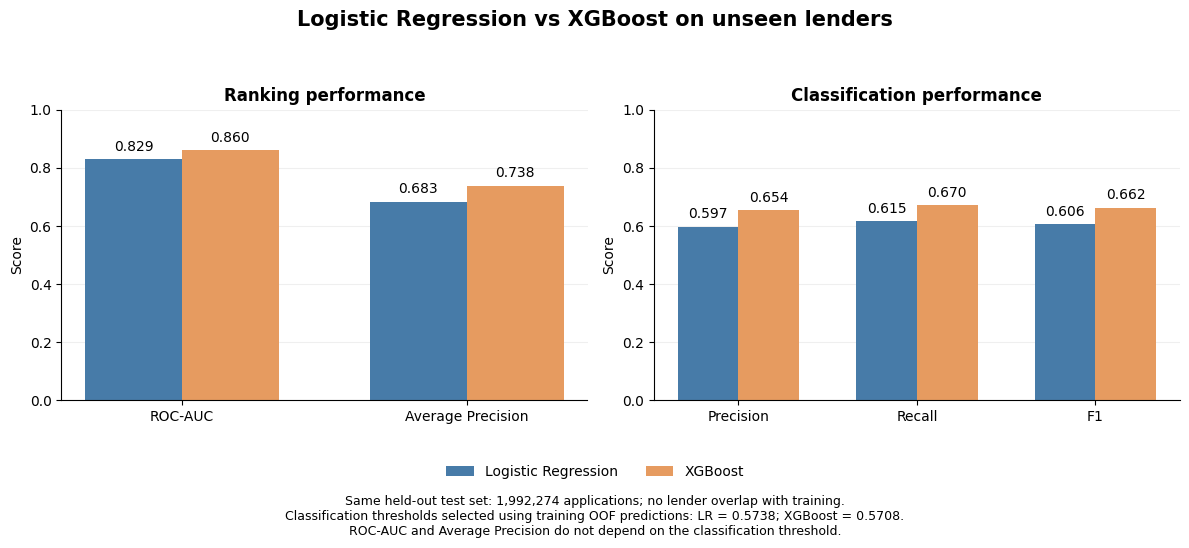

Đã lưu: /content/drive/MyDrive/HMDA_Thuy/rq4_gradient_boosting/figures/01_lr_xgb_test_performance.png
PASS — đã tạo biểu đồ so sánh mô hình.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc bảng so sánh đã lưu
GB_OUT = Path(
    "/content/drive/MyDrive/HMDA_Thuy/rq4_gradient_boosting"
)

GB_FIGURES = GB_OUT / "figures"
GB_FIGURES.mkdir(parents=True, exist_ok=True)

comparison = pd.read_csv(
    GB_OUT / "21_lr_xgb_test_comparison.csv"
)

model_order = ["Logistic Regression", "XGBoost"]

selected = (
    comparison.loc[
        comparison["threshold_type"].eq("Optimized")
    ]
    .set_index("model")
    .reindex(model_order)
)

assert len(selected) == 2
assert selected.index.is_unique

# 2. Hai nhóm chỉ số
panels = [
    (
        ["roc_auc", "average_precision"],
        ["ROC-AUC", "Average Precision"],
        "Ranking performance",
    ),
    (
        ["precision", "recall", "f1"],
        ["Precision", "Recall", "F1"],
        "Classification performance",
    ),
]

colors = {
    "Logistic Regression": "#477BA8",
    "XGBoost": "#E69B60",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for ax, (metrics, labels, title) in zip(axes, panels):
    x = np.arange(len(metrics))
    width = 0.34

    for i, model_name in enumerate(model_order):
        values = selected.loc[model_name, metrics].to_numpy(
            dtype=float
        )

        assert np.isfinite(values).all()

        bars = ax.bar(
            x + (i - 0.5) * width,
            values,
            width,
            color=colors[model_name],
            label=model_name,
        )

        ax.bar_label(
            bars,
            labels=[f"{value:.3f}" for value in values],
            padding=4,
            fontsize=10,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.suptitle(
    "Logistic Regression vs XGBoost on unseen lenders",
    fontsize=15,
    fontweight="bold",
    y=0.98,
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.105),
    ncol=2,
    frameon=False,
)

lr_threshold = float(
    selected.loc["Logistic Regression", "threshold"]
)
xgb_threshold = float(
    selected.loc["XGBoost", "threshold"]
)

fig.text(
    0.5,
    0.025,
    "Same held-out test set: 1,992,274 applications; "
    "no lender overlap with training.\n"
    "Classification thresholds selected using training OOF predictions: "
    f"LR = {lr_threshold:.4f}; XGBoost = {xgb_threshold:.4f}.\n"
    "ROC-AUC and Average Precision do not depend on the classification threshold.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.20, 1, 0.93])

figure_path = GB_FIGURES / "01_lr_xgb_test_performance.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)

print("Đã lưu:", figure_path)
print("PASS — đã tạo biểu đồ so sánh mô hình.")

BẢNG 1 — ĐỘ QUAN TRỌNG THEO BIẾN GỐC


,original_feature,total_gain,split_count,share_of_total_gain_pct
0,dti_band,7730198.520,797.0,45.434
1,loan_purpose,2641023.593,675.0,15.523
2,construction_method,1706646.500,149.0,10.031
3,property_value,1093922.938,729.0,6.430
4,log_loan_amount,827235.938,390.0,4.862
5,loan_type,774028.848,506.0,4.549
6,combined_loan_to_value_ratio,767047.031,915.0,4.508
7,log_income,508332.750,536.0,2.988
8,state_code,411542.141,534.0,2.419
9,loan_to_income,222647.906,378.0,1.309



BẢNG 2 — 15 CỘT MÃ HÓA QUAN TRỌNG NHẤT


,encoded_feature,total_gain,split_count,original_feature,share_of_total_gain_pct
0,categorical__dti_band_>60%,5499504.000,106.0,dti_band,32.323
1,categorical__loan_purpose_1,2231770.500,277.0,loan_purpose,13.117
2,categorical__construction_method_1,1706646.500,149.0,construction_method,10.031
3,categorical__dti_band_50-60%,999095.312,186.0,dti_band,5.872
4,categorical__dti_band_Not provided,911742.500,327.0,dti_band,5.359
5,numeric_identity__log_loan_amount,827235.938,390.0,log_loan_amount,4.862
6,missing_indicator__missingindicator_property_v...,756056.562,353.0,property_value,4.444
7,numeric_identity__combined_loan_to_value_ratio,660648.688,722.0,combined_loan_to_value_ratio,3.883
8,categorical__loan_type_1,529342.500,242.0,loan_type,3.111
9,numeric_log__property_value,337866.375,376.0,property_value,1.986


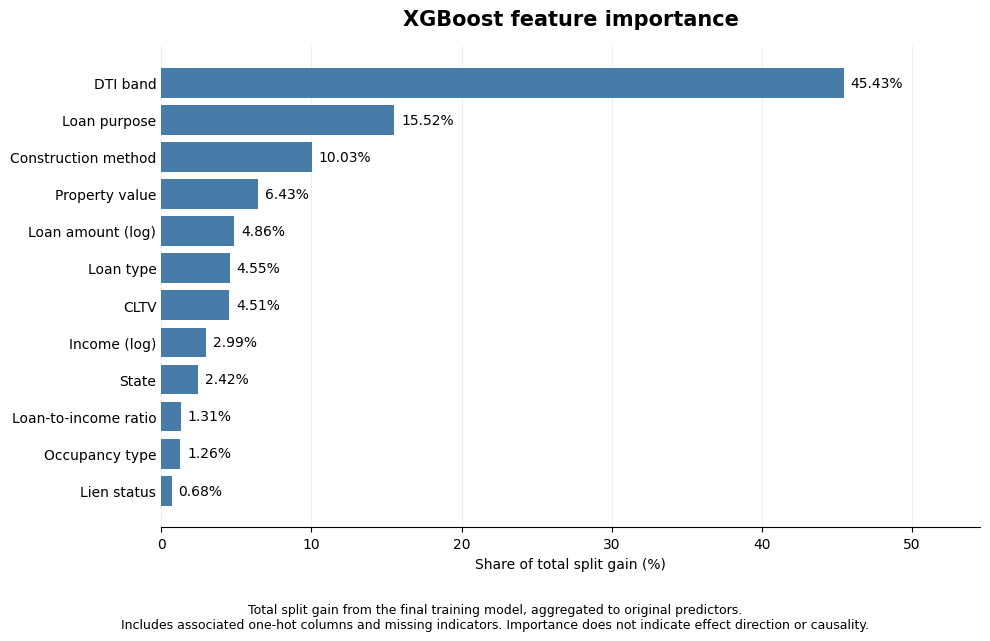


Đã lưu: /content/drive/MyDrive/HMDA_Thuy/rq4_gradient_boosting/figures/02_xgb_grouped_feature_importance.png
PASS — đã xuất bảng và biểu đồ độ quan trọng.


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from IPython.display import display

# 1. Đọc thiết lập, tên cột và mô hình đã lưu
BASE = Path("/content/drive/MyDrive/hmda")
GB_OUT = Path(
    "/content/drive/MyDrive/HMDA_Thuy/rq4_gradient_boosting"
)
GB_FIGURES = GB_OUT / "figures"
GB_FIGURES.mkdir(parents=True, exist_ok=True)

with open(
    BASE / "rq4_setup/master_modeling_config.json",
    encoding="utf-8",
) as f:
    model_config = json.load(f)

original_features = model_config[
    "configurations"
]["feature_selection"]["features"]

encoded_names = pd.read_csv(
    GB_OUT / "16_xgb_encoded_features.csv"
)["encoded_feature"].tolist()

booster = xgb.Booster()
booster.load_model(str(GB_OUT / "14_xgb_final_model.ubj"))

assert booster.num_features() == len(encoded_names)

# 2. Lấy độ quan trọng cho từng cột mã hóa
# Các cột không được dùng để chia cây có importance = 0
total_gain_scores = booster.get_score(importance_type="total_gain")
split_count_scores = booster.get_score(importance_type="weight")

model_feature_keys = (
    booster.feature_names
    if booster.feature_names is not None
    else [f"f{i}" for i in range(len(encoded_names))]
)

assert len(model_feature_keys) == len(encoded_names)
assert set(total_gain_scores).issubset(set(model_feature_keys))

encoded_importance = pd.DataFrame({
    "encoded_feature": encoded_names,
    "total_gain": [
        total_gain_scores.get(key, 0.0)
        for key in model_feature_keys
    ],
    "split_count": [
        split_count_scores.get(key, 0.0)
        for key in model_feature_keys
    ],
})

# 3. Xác định biến gốc của từng cột
def get_original_feature(encoded_name):
    block, name = encoded_name.split("__", 1)

    if block == "missing_indicator":
        prefix = "missingindicator_"
        assert name.startswith(prefix), encoded_name
        original = name[len(prefix):]
        assert original in original_features, encoded_name
        return original

    if block == "categorical":
        candidates = [
            feature
            for feature in original_features
            if name.startswith(feature + "_")
        ]
        assert len(candidates) == 1, (
            f"Không xác định được biến gốc: {encoded_name}"
        )
        return candidates[0]

    # Các cột số giữ tên đầu vào dù đã được biến đổi
    assert name in original_features, encoded_name
    return name

encoded_importance["original_feature"] = (
    encoded_importance["encoded_feature"].map(
        get_original_feature
    )
)

total_gain_sum = encoded_importance["total_gain"].sum()
assert total_gain_sum > 0

encoded_importance["share_of_total_gain_pct"] = (
    encoded_importance["total_gain"] / total_gain_sum * 100
)

encoded_importance = encoded_importance.sort_values(
    "total_gain", ascending=False
).reset_index(drop=True)

# 4. Cộng về 12 biến gốc
grouped_importance = (
    encoded_importance
    .groupby("original_feature")[["total_gain", "split_count"]]
    .sum()
    .reindex(original_features, fill_value=0)
    .reset_index()
)

grouped_importance["share_of_total_gain_pct"] = (
    grouped_importance["total_gain"] / total_gain_sum * 100
)

grouped_importance = grouped_importance.sort_values(
    "total_gain", ascending=False
).reset_index(drop=True)

assert len(grouped_importance) == 12
assert np.isclose(
    grouped_importance["share_of_total_gain_pct"].sum(), 100
)

print("BẢNG 1 — ĐỘ QUAN TRỌNG THEO BIẾN GỐC")
display(grouped_importance.round(3))

print("\nBẢNG 2 — 15 CỘT MÃ HÓA QUAN TRỌNG NHẤT")
display(encoded_importance.head(15).round(3))

# 5. Lưu bảng đầy đủ
encoded_importance.to_csv(
    GB_OUT / "23_xgb_encoded_importance.csv",
    index=False,
    encoding="utf-8-sig",
)

grouped_importance.to_csv(
    GB_OUT / "24_xgb_grouped_importance.csv",
    index=False,
    encoding="utf-8-sig",
)

# 6. Vẽ biểu đồ
readable_labels = {
    "log_income": "Income (log)",
    "log_loan_amount": "Loan amount (log)",
    "loan_to_income": "Loan-to-income ratio",
    "property_value": "Property value",
    "combined_loan_to_value_ratio": "CLTV",
    "loan_type": "Loan type",
    "loan_purpose": "Loan purpose",
    "lien_status": "Lien status",
    "occupancy_type": "Occupancy type",
    "construction_method": "Construction method",
    "state_code": "State",
    "dti_band": "DTI band",
}

plot_data = grouped_importance.copy()
plot_data["label"] = plot_data["original_feature"].map(
    readable_labels
)

fig, ax = plt.subplots(figsize=(10, 6.5))

bars = ax.barh(
    plot_data["label"],
    plot_data["share_of_total_gain_pct"],
    color="#477BA8",
)

ax.invert_yaxis()

ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in plot_data["share_of_total_gain_pct"]
    ],
    padding=5,
    fontsize=10,
)

ax.set_xlim(
    0,
    max(1, plot_data["share_of_total_gain_pct"].max()) * 1.2,
)

ax.set_xlabel("Share of total split gain (%)")
ax.set_title(
    "XGBoost feature importance",
    fontsize=15,
    fontweight="bold",
    pad=15,
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

ax.tick_params(axis="y", length=0)

fig.text(
    0.5,
    0.025,
    "Total split gain from the final training model, "
    "aggregated to original predictors.\n"
    "Includes associated one-hot columns and missing indicators. "
    "Importance does not indicate effect direction or causality.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

figure_path = GB_FIGURES / "02_xgb_grouped_feature_importance.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)

print("\nĐã lưu:", figure_path)
print("PASS — đã xuất bảng và biểu đồ độ quan trọng.")